# Jalon A — Kalman / EKF, une cible

Un radar marin à l'origine mesure la **distance** et l'**angle** d'un navire toutes les 2 s
(période de rotation de l'antenne). L'état du filtre est cartésien `[x, y, vx, vy]`.

Trois questions, trois figures :

1. L'EKF polaire suit-il une cible qui tourne ? (trajectoire vraie / mesures / estimation)
2. Le filtre est-il **honnête** sur son incertitude ? (NEES / NIS sur 100 Monte-Carlo)
3. Que se passe-t-il quand **Q est faux** ? (RMSE en fonction d'un facteur d'erreur sur Q)

Tout le filtrage est codé à la main dans `src/tracking/` ; `filterpy` n'est utilisé que dans `tests/`.

In [1]:
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np

from metrics.nees import chi2_interval, nees, nis
from metrics.rmse import position_rmse, rmse_per_step
from sim.trajectories import (
    TrajectoryParams,
    maneuver_trajectory,
    polar_measurements,
    process_noise_cv,
    transition_cv,
)
from tracking.ekf import ExtendedKalmanFilter, polar_to_cartesian
from tracking.kf import run_filter, run_monte_carlo

# --- style des figures : encre et surfaces neutres, palette catégorielle validée (slots 1 à 3)
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.grid": True, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.8, "lines.solid_capstyle": "round", "font.family": "sans-serif",
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 160,
})
FIG_DIR = "../figures"

## Scénario et paramètres

Un navire de 15 m/s : ligne droite (CV), virage à 0,02 rad/s (≈ 1,15 °/s, rayon 750 m), ligne droite.
Le filtre n'a **qu'un modèle CV** : pendant le virage son modèle est faux, c'est volontaire.
`σ_a` = 0,05 m/s² est l'accélération aléatoire « normale » (Q nominal) ; le virage impose en réalité
une accélération de v·ω = 0,3 m/s², 6 fois plus.

In [2]:
@dataclass(frozen=True)
class ScenarioA:
    dt: float = 2.0                                   # période d'antenne [s]
    sigma_a: float = 0.05                             # accélération aléatoire de la vérité [m/s²]
    sigma_r: float = 25.0                             # bruit de distance [m]
    sigma_theta: float = 0.01                         # bruit d'angle [rad] (0,57°)
    x0: tuple = (-6_000.0, 3_000.0, 0.0, -15.0)       # état initial [x, y, vx, vy]
    p0_diag: tuple = (100.0**2, 100.0**2, 5.0**2, 5.0**2)
    turn_rate: float = 0.02                           # taux de virage [rad/s]
    n_runs: int = 100                                 # tirages Monte-Carlo

SC = ScenarioA()
CV_ONLY = [(130, 0.0)]
TURN = [(40, 0.0), (50, SC.turn_rate), (40, 0.0)]     # mêmes 131 instants dans les deux cas
P0 = np.diag(SC.p0_diag)
R_POLAR = np.diag([SC.sigma_r**2, SC.sigma_theta**2])


def simulate(rng, segments):
    # Vérité (modèle de mouvement par segments) et mesures polaires bruitées.
    params = TrajectoryParams(dt=SC.dt, sigma_a=SC.sigma_a)
    truth = maneuver_trajectory(np.array(SC.x0), segments, params, rng)
    return truth, polar_measurements(truth, SC.sigma_r, SC.sigma_theta, rng)


def make_ekf(sigma_a_filter):
    # Fabrique d'EKF : a priori tiré selon N(x_vrai, P0), Q construit avec σ_a du filtre.
    def factory(rng, truth):
        x0 = truth[0] + np.linalg.cholesky(P0) @ rng.standard_normal(4)
        return ExtendedKalmanFilter(
            transition_cv(SC.dt), process_noise_cv(SC.dt, sigma_a_filter), R_POLAR, x0, P0
        )
    return factory


def monte_carlo(segments, sigma_a_filter, n_runs=SC.n_runs, seed=0):
    return run_monte_carlo(n_runs, lambda rng: simulate(rng, segments), make_ekf(sigma_a_filter), seed)

## Figure 1 — Trajectoire vraie, mesures, estimation

À gauche, un tirage : l'EKF à Q nominal suit la ligne droite mais **décroche dans le virage** : il croit à une
trajectoire rectiligne, réagit avec retard et sort de la courbe vers l'extérieur. À droite, l'erreur de position moyenne (50 tirages)
pour Q nominal et pour un Q 100 fois plus grand (σ_a × 10) : le second encaisse le virage mais bruite
davantage la ligne droite.

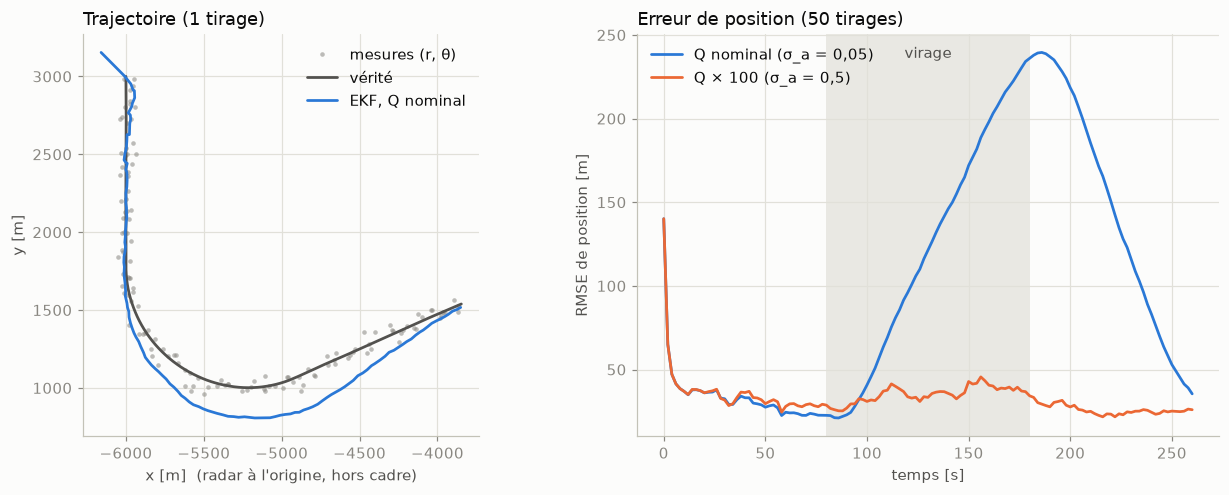

In [3]:
rng = np.random.default_rng(1)
truth, z = simulate(rng, TURN)
x0_est = truth[0] + np.linalg.cholesky(P0) @ rng.standard_normal(4)
nominal = run_filter(
    ExtendedKalmanFilter(transition_cv(SC.dt), process_noise_cv(SC.dt, SC.sigma_a), R_POLAR, x0_est, P0), z
)
meas_xy = np.array([polar_to_cartesian(r, th) for r, th in z])

mc_nominal = monte_carlo(TURN, SC.sigma_a, n_runs=50, seed=10)
mc_inflated = monte_carlo(TURN, 10 * SC.sigma_a, n_runs=50, seed=10)
t = SC.dt * np.arange(len(truth))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})
ax1.plot(meas_xy[1:, 0], meas_xy[1:, 1], "o", ms=3, color=MUTED, alpha=0.55, mew=0, label="mesures (r, θ)")
ax1.plot(truth[:, 0], truth[:, 1], color=INK2, label="vérité")
ax1.plot(nominal.x[:, 0], nominal.x[:, 1], color=BLUE, label="EKF, Q nominal")
ax1.set_aspect("equal")
ax1.set_xlabel("x [m]  (radar à l'origine, hors cadre)")
ax1.set_ylabel("y [m]")
ax1.set_title("Trajectoire (1 tirage)", loc="left", color=INK)
ax1.legend(loc="upper right")

ax2.axvspan(t[40], t[90], color=GRID, alpha=0.7, lw=0)
ax2.text(t[65], 0.97, "virage", ha="center", va="top", color=INK2, transform=ax2.get_xaxis_transform())
ax2.plot(t, rmse_per_step(mc_nominal.x_true, mc_nominal.x), color=BLUE, label="Q nominal (σ_a = 0,05)")
ax2.plot(t, rmse_per_step(mc_inflated.x_true, mc_inflated.x), color=ORANGE, label="Q × 100 (σ_a = 0,5)")
ax2.set_xlabel("temps [s]")
ax2.set_ylabel("RMSE de position [m]")
ax2.set_title("Erreur de position (50 tirages)", loc="left", color=INK)
ax2.legend(loc="upper left")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/A_trajectoire.png")
plt.show()

## Figure 2 — Le filtre est-il honnête ? NEES et NIS

Si P décrit bien l'erreur réelle, le NEES moyen vaut 4 (dimension de l'état) et le NIS moyen 2 (dimension de
la mesure). La bande grise est l'intervalle χ² à 95 % de la moyenne sur 100 tirages. Trois cas :

- **CV, Q correct** : dans la bande, le filtre est honnête ;
- **virage, Q nominal** : NEES ≫ 4, le filtre est *trop sûr de lui* ;
- **CV, Q 100 fois trop petit** : NEES ≫ 4 aussi (≈ 68 en moyenne), mais le **NIS reste proche de la bande**
  (2,2 en moyenne, contre 1,6–2,4 attendu, avec une lente dérive vers 3) : le NIS voit bien moins que le NEES.

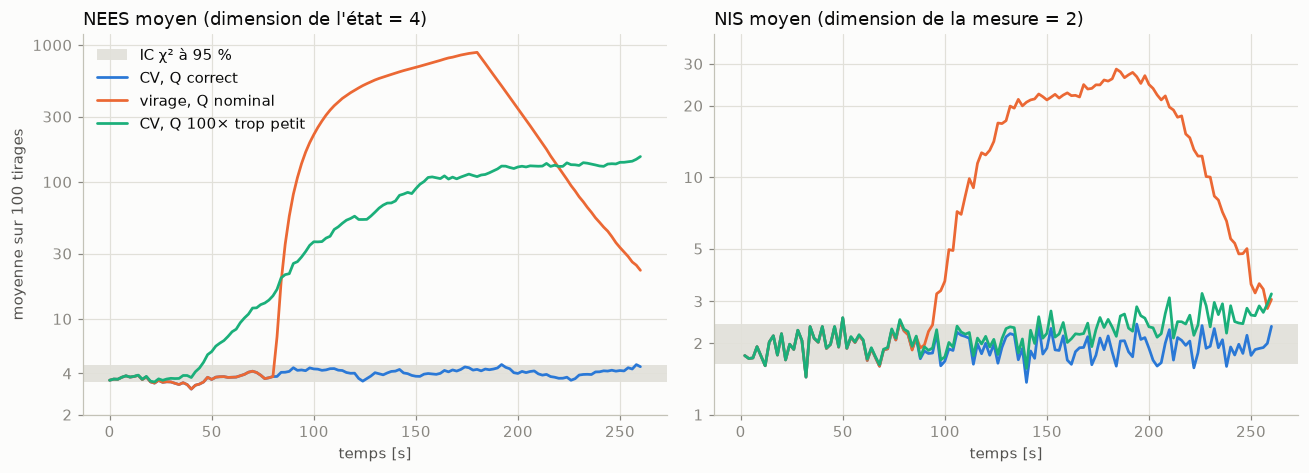

cas                         NEES moyen          IC NEES  NIS moyen           IC NIS
CV, Q correct                     3.96 [ 3.46,  4.57]       1.95 [ 1.63,  2.41]
virage, Q nominal               262.42 [ 3.46,  4.57]      10.92 [ 1.63,  2.41]
CV, Q 100× trop petit            67.95 [ 3.46,  4.57]       2.22 [ 1.63,  2.41]


In [4]:
cases = {
    "CV, Q correct": (CV_ONLY, SC.sigma_a, BLUE),
    "virage, Q nominal": (TURN, SC.sigma_a, ORANGE),
    "CV, Q 100× trop petit": (CV_ONLY, SC.sigma_a / 10, AQUA),
}
stats = {}
for name, (segments, sigma_a_f, _) in cases.items():
    mc = monte_carlo(segments, sigma_a_f, seed=21)
    stats[name] = (nees(mc.x_true, mc.x, mc.P).mean(axis=0), nis(mc.innovations, mc.S).mean(axis=0))

lo4, hi4 = chi2_interval(4, SC.n_runs)
lo2, hi2 = chi2_interval(2, SC.n_runs)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4), sharex=True)
for ax, idx, (lo, hi), dof, title in [
    (ax1, 0, (lo4, hi4), 4, "NEES moyen (dimension de l'état = 4)"),
    (ax2, 1, (lo2, hi2), 2, "NIS moyen (dimension de la mesure = 2)"),
]:
    ax.axhspan(lo, hi, color=GRID, alpha=0.9, lw=0, label="IC χ² à 95 %")
    for name, (_, _, color) in cases.items():
        ax.plot(t, stats[name][idx], color=color, label=name)
    ax.set_yscale("log")
    ticks = [2, 4, 10, 30, 100, 300, 1000] if idx == 0 else [1, 2, 3, 5, 10, 20, 30]
    ax.set_yticks(ticks, labels=[str(v) for v in ticks])
    ax.minorticks_off()
    ax.set_ylim(top=1200 if idx == 0 else 40)
    ax.set_xlabel("temps [s]")
    ax.set_title(title, loc="left", color=INK)
ax1.set_ylabel("moyenne sur 100 tirages")
ax1.legend(loc="upper left")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/A_nees.png")
plt.show()

print(f"{'cas':26s} {'NEES moyen':>11s} {'IC NEES':>16s} {'NIS moyen':>10s} {'IC NIS':>16s}")
for name, (n_k, v_k) in stats.items():
    print(f"{name:26s} {n_k.mean():11.2f} [{lo4:5.2f}, {hi4:5.2f}] {np.nanmean(v_k):10.2f} [{lo2:5.2f}, {hi2:5.2f}]")

## Figure 3 — Q faux : RMSE en fonction du facteur d'erreur sur Q

On multiplie le Q du filtre par un facteur `f` (f = 1 : le Q de la vérité). Deux scénarios :
trajectoire CV (le modèle est juste) et trajectoire avec virage (le modèle CV est faux).

- Sur la trajectoire **CV**, le minimum est à f ≈ 1 (21 m) : Q trop petit ou trop grand dégrade, lentement.
- Dans le **virage**, f = 1 donne 130 m, plus de 4 fois le meilleur résultat (30 m à f ≈ 100) : Q trop petit
  → le filtre décroche.
- Un Q fixe est donc un **compromis** : f = 100 sauve le virage (30 m) mais coûte en ligne droite
  (29 m au lieu de 21 m, soit +37 %). Cette tension, entre précision en ligne droite et réactivité en
  manœuvre, est la motivation de l'IMM (jalon C) et des approches apprises (jalon D).

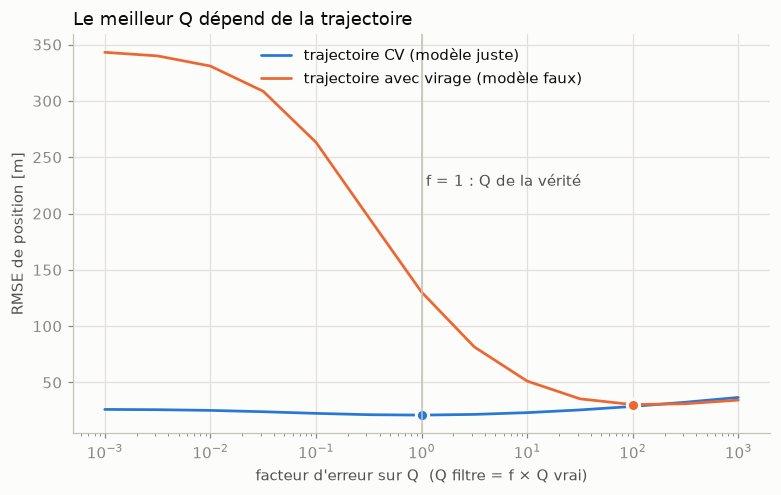

        f  RMSE CV [m]  RMSE virage [m]
    0.001         26.1            343.1
  0.00316         25.8            339.9
     0.01         25.2            330.9
   0.0316         24.0            308.6
      0.1         22.6            263.3
    0.316         21.4            196.5
        1         21.0            130.3
     3.16         21.6             81.5
       10         23.2             51.2
     31.6         25.6             35.5
      100         28.7             30.3
      316         32.5             31.1
    1e+03         36.7             34.3
meilleur f : {'CV': '1', 'virage': '100'}


In [5]:
factors = np.logspace(-3, 3, 13)                      # facteur multiplicatif sur Q
rmse = {"CV": [], "virage": []}
for f in factors:
    for label, segments in [("CV", CV_ONLY), ("virage", TURN)]:
        mc = monte_carlo(segments, SC.sigma_a * np.sqrt(f), n_runs=50, seed=31)
        rmse[label].append(position_rmse(mc.x_true, mc.x, skip=10))
rmse = {k: np.array(v) for k, v in rmse.items()}

fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.plot(factors, rmse["CV"], color=BLUE, label="trajectoire CV (modèle juste)")
ax.plot(factors, rmse["virage"], color=ORANGE, label="trajectoire avec virage (modèle faux)")
for key, color in [("CV", BLUE), ("virage", ORANGE)]:
    i = int(np.argmin(rmse[key]))
    ax.plot(factors[i], rmse[key][i], "o", ms=8, color=color, mec=SURFACE, mew=2)
ax.axvline(1.0, color=AXIS, lw=1)
ax.text(1.1, 0.62, "f = 1 : Q de la vérité", color=INK2, transform=ax.get_xaxis_transform())
ax.set_xscale("log")
ax.set_xlabel("facteur d'erreur sur Q  (Q filtre = f × Q vrai)")
ax.set_ylabel("RMSE de position [m]")
ax.set_title("Le meilleur Q dépend de la trajectoire", loc="left", color=INK)
ax.legend(loc="upper center")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/A_rmse_vs_q.png")
plt.show()

print(f"{'f':>9s} {'RMSE CV [m]':>12s} {'RMSE virage [m]':>16s}")
for f, a, b in zip(factors, rmse["CV"], rmse["virage"]):
    print(f"{f:9.3g} {a:12.1f} {b:16.1f}")
best = {k: factors[int(np.argmin(v))] for k, v in rmse.items()}
print("meilleur f :", {k: f"{v:.3g}" for k, v in best.items()})

## Ce qu'on retient

- L'EKF polaire → cartésien est **honnête** (NEES ≈ 4, NIS ≈ 2) tant que le modèle de mouvement est juste.
- Le passage de θ = ±π est géré par la **normalisation de l'innovation d'angle** (test dans `tests/test_ekf.py`).
- Avec un modèle faux (virage), le filtre devient **trop sûr de lui** : l'erreur augmente *et* le NEES explose
  (≈ 260 en moyenne contre 4 attendu).
- Le NIS seul ne suffit pas : un Q trop petit sur une trajectoire droite se voit à peine dans le NIS, très bien dans le NEES
  (qui, lui, demande la vérité terrain, donc n'est utilisable qu'en simulation).